In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

root = Path.cwd()
while not (root / "requirements.txt").exists() and root != root.parent:
    root = root.parent
sys.path.append(str(root))

from src.features import build_features

df = pd.read_parquet(root / "data" / "processed" / "kuala_lumpur_clean.parquet")
feat = build_features(df)
print(feat.shape)

(36568, 37)


In [2]:
H = 24
data = feat.copy()
data["y"] = data["pm2_5"].shift(-H)     # PM2.5 24 hours from now
data["seasonal_naive"] = data["pm2_5"].shift(24 - H)   # see note below

# Drop rows with missing values (first 72 hours, last 24 hours, the glitch)
data = data.dropna()
print(data.shape)

(36316, 39)


In [3]:
n = len(data)
i1, i2 = int(n * 0.70), int(n * 0.85)

train = data.iloc[: i1 - H]
valid = data.iloc[i1 : i2 - H]
test  = data.iloc[i2 :]

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(name, len(part), part.index.min().date(), "to", part.index.max().date())

train 25397 2022-08-07 to 2025-07-07
valid 5423 2025-07-08 to 2026-02-18
test 5448 2026-02-20 to 2026-10-04


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def report(name, y, pred):
    mae = mean_absolute_error(y, pred)
    rmse = mean_squared_error(y, pred) ** 0.5
    print(f"{name:20s} MAE {mae:6.2f}   RMSE {rmse:6.2f}")

report("persistence (now)", test["y"], test["pm2_5"])
report("mean of last 24h", test["y"], test["pm25_mean_24"])
report("train average", test["y"], np.full(len(test), train["y"].mean()))

persistence (now)    MAE  15.84   RMSE  22.34
mean of last 24h     MAE  19.64   RMSE  25.67
train average        MAE  19.17   RMSE  26.28


In [5]:
import lightgbm as lgb

drop_cols = ["y", "seasonal_naive", "is_glitch"]
cols = [c for c in data.columns if c not in drop_cols]
print(len(cols), "features")

model = lgb.LGBMRegressor(
    n_estimators=2000, learning_rate=0.03, num_leaves=31,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1,
)
model.fit(
    train[cols], train["y"],
    eval_set=[(valid[cols], valid["y"])],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
print("Trees used:", model.best_iteration_)

36 features


c:\Users\maymy\OneDrive\Documents\air quality forecaster\air-quality-forecaster\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Trees used: 129


In [6]:
pred = np.clip(model.predict(test[cols]), 0, None)   # PM2.5 can't be negative

report("LightGBM", test["y"], pred)
report("persistence (now)", test["y"], test["pm2_5"])

base_mae = mean_absolute_error(test["y"], test["pm2_5"])
model_mae = mean_absolute_error(test["y"], pred)
print(f"\nMAE improvement over persistence: {(1 - model_mae / base_mae):.1%}")

LightGBM             MAE  13.64   RMSE  19.52
persistence (now)    MAE  15.84   RMSE  22.34

MAE improvement over persistence: 13.9%


In [7]:
imp = pd.Series(model.feature_importances_, index=cols).sort_values(ascending=False)
print(imp.head(10))

rain_sum_24        305
pm25_mean_72       278
month_cos          219
pm25_lag_24        199
pm25_lag_72        198
pm25_std_72        197
pm2_5              197
pm25_lag_48        188
pm10               156
carbon_monoxide    149
dtype: int32


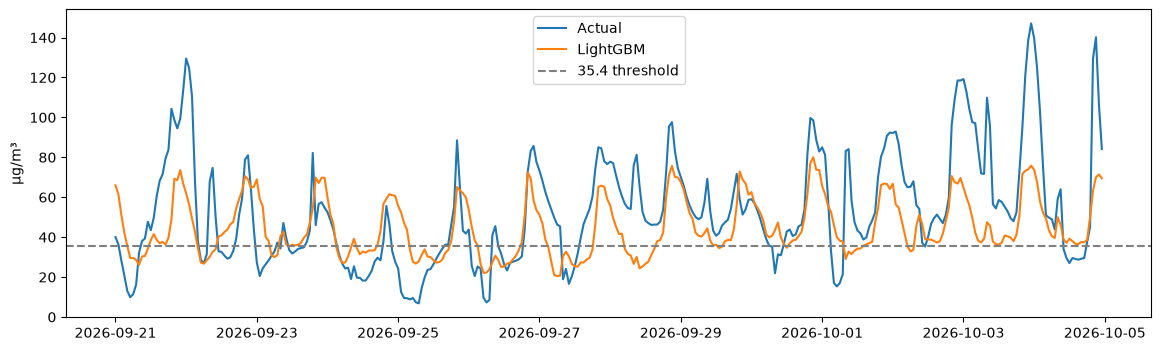

In [8]:
import matplotlib.pyplot as plt

last = test.iloc[-24 * 14:]            # last 14 days
p = pd.Series(pred, index=test.index).loc[last.index]
plt.figure(figsize=(14, 4))
plt.plot(last.index, last["y"], label="Actual")
plt.plot(last.index, p, label="LightGBM")
plt.axhline(35.4, color="gray", linestyle="--", label="35.4 threshold")
plt.legend()
plt.ylabel("µg/m³")
plt.show()


In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

T = 35.4
yt = test["y"] > T
for name, p_ in [("persistence", test["pm2_5"]), ("LightGBM", pred)]:
    yp = p_ > T
    print(f"{name:12s} precision {precision_score(yt, yp):.2f}  "
          f"recall {recall_score(yt, yp):.2f}  F1 {f1_score(yt, yp):.2f}")
print("Share of test hours above threshold:", round(yt.mean(), 3))

persistence  precision 0.77  recall 0.77  F1 0.77
LightGBM     precision 0.79  recall 0.81  F1 0.80
Share of test hours above threshold: 0.556


In [10]:
test["y"].mean()

np.float64(45.28314977973568)

In [11]:
for T in [35.4, 55.4]:
    yt = test["y"] > T
    print(f"\nThreshold {T}: {yt.mean():.1%} of test hours are above it")
    for name, p_ in [("persistence", test["pm2_5"]), ("LightGBM", pred)]:
        yp = p_ > T
        print(f"  {name:12s} precision {precision_score(yt, yp, zero_division=0):.2f}  "
              f"recall {recall_score(yt, yp, zero_division=0):.2f}  "
              f"F1 {f1_score(yt, yp, zero_division=0):.2f}")
    print(f"  always-alert  precision {yt.mean():.2f}  recall 1.00")


Threshold 35.4: 55.6% of test hours are above it
  persistence  precision 0.77  recall 0.77  F1 0.77
  LightGBM     precision 0.79  recall 0.81  F1 0.80
  always-alert  precision 0.56  recall 1.00

Threshold 55.4: 27.6% of test hours are above it
  persistence  precision 0.63  recall 0.63  F1 0.63
  LightGBM     precision 0.67  recall 0.60  F1 0.63
  always-alert  precision 0.28  recall 1.00


In [12]:
def fit_quantile(alpha):
    m = lgb.LGBMRegressor(
        objective="quantile", alpha=alpha,
        n_estimators=2000, learning_rate=0.03, num_leaves=31,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, verbose=-1,
    )
    m.fit(train[cols], train["y"],
          eval_set=[(valid[cols], valid["y"])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m

q10, q90 = fit_quantile(0.1), fit_quantile(0.9)

lo = np.clip(q10.predict(test[cols]), 0, None)
hi = np.clip(q90.predict(test[cols]), 0, None)
lo, hi = np.minimum(lo, pred), np.maximum(hi, pred)   # keep the range around the forecast

inside = (test["y"] >= lo) & (test["y"] <= hi)
print(f"Coverage of the 80% interval: {inside.mean():.1%}")
print(f"Average interval width: {(hi - lo).mean():.1f} µg/m³")
high = test["y"] > 55.4
print(f"Coverage when the real value is above 55.4: {inside[high].mean():.1%}")

c:\Users\maymy\OneDrive\Documents\air quality forecaster\air-quality-forecaster\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\maymy\OneDrive\Documents\air quality forecaster\air-quality-forecaster\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Coverage of the 80% interval: 74.7%
Average interval width: 36.4 µg/m³
Coverage when the real value is above 55.4: 57.5%


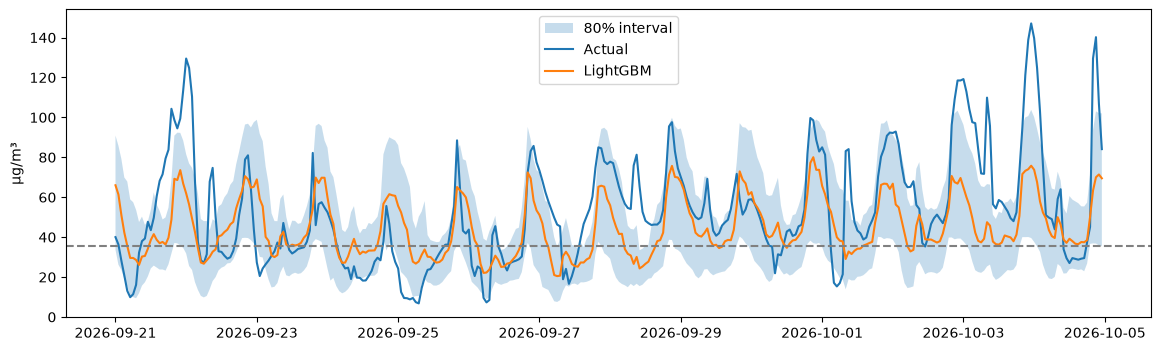

In [13]:
last = test.iloc[-24 * 14:]
idx = last.index
plt.figure(figsize=(14, 4))
plt.fill_between(idx, pd.Series(lo, index=test.index).loc[idx],
                 pd.Series(hi, index=test.index).loc[idx],
                 alpha=0.25, label="80% interval")
plt.plot(idx, last["y"], label="Actual")
plt.plot(idx, pd.Series(pred, index=test.index).loc[idx], label="LightGBM")
plt.axhline(35.4, color="gray", linestyle="--")
plt.legend(); plt.ylabel("µg/m³")
plt.show()